**Task 1 - PCA**

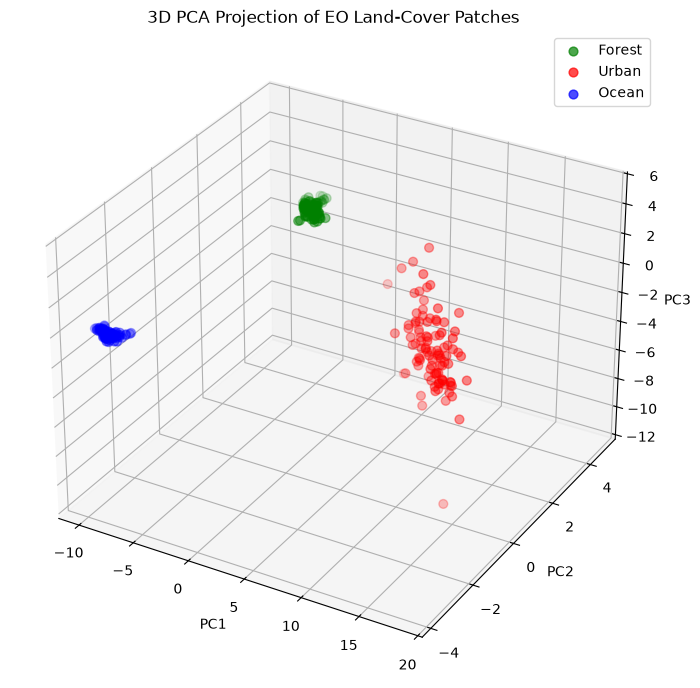

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.decomposition import PCA

def extract_patches(image_path, patch_size=64, max_patches=100):
    img = np.array(Image.open(image_path))[:, :, :3] / 255.0
    h, w, _ = img.shape
    patches = []
    for y in range(0, h - patch_size + 1, patch_size):
        for x in range(0, w - patch_size + 1, patch_size):
            patch = img[y:y + patch_size, x:x + patch_size, :]
            patches.append(patch.flatten())
            if len(patches) >= max_patches:
                return np.array(patches)
    return np.array(patches)

forest = extract_patches('D:/agh/Machine-Learing/2026-08-25-00_00_2026-08-25-23_59_Sentinel-2_L2A_True_color.tiff', patch_size=64)
urban = extract_patches('D:/agh/Machine-Learing/2026-10-08-00_00_2026-10-08-23_59_Sentinel-2_L2A_True_color.tiff', patch_size=64)
ocean = extract_patches('D:/agh/Machine-Learing/2026-04-03-00_00_2026-04-03-23_59_Sentinel-2_L2A_True_color.tiff', patch_size=64)

X = np.vstack([forest, urban, ocean])
y = np.array(
    [0] * len(forest) +
    [1] * len(urban) +
    [2] * len(ocean)
)

pca = PCA(n_components=3)
X_pca = pca.fit_transform(X)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')

labels = ['Forest', 'Urban', 'Ocean']
colors = ['green', 'red', 'blue']

for cls_idx, (label, color) in enumerate(zip(labels, colors)):
    ax.scatter(
        X_pca[y == cls_idx, 0],
        X_pca[y == cls_idx, 1],
        X_pca[y == cls_idx, 2],
        c=color,
        label=label,
        alpha=0.7,
        s=40
    )

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('3D PCA Projection of EO Land-Cover Patches')
ax.legend()
plt.tight_layout()
plt.show()

**Finding:**

When projecting the flattened RGB patches into the first three PCs, distinct clusters emerge corresponding to each land-cover class. Because PC1 and PC2 capture the directions of maximum variance—primarily driven by overall brightness and dominant spectral channels the classes separate well. Cluters for forest and ocean are well clustered while the urban cluster is more dispersed due to its less uniform structure.

**Task 2 - Auto encoder**

PSNR Bicubic: 31.81 dB | PSNR Autoencoder: 31.79 dB


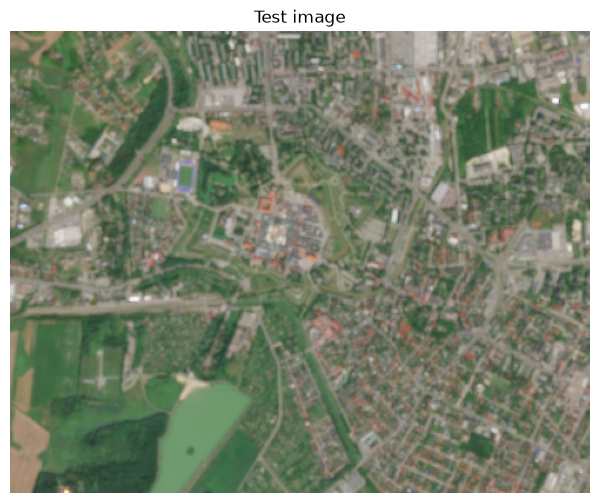

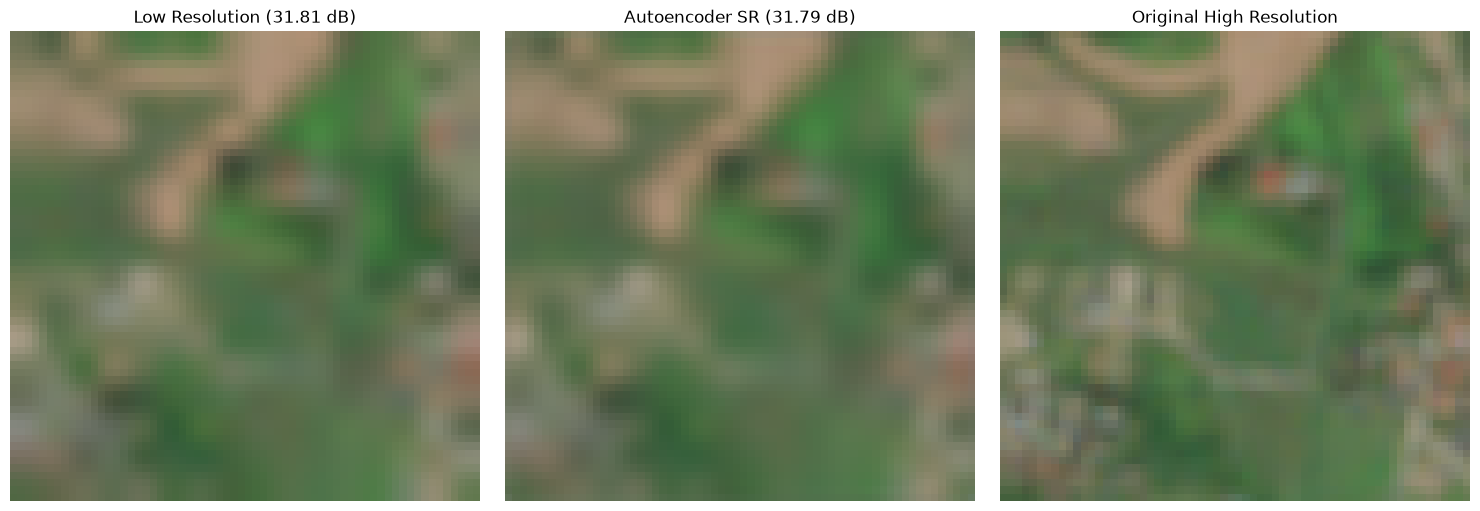

In [ ]:
import tensorflow as tf

img = Image.open('D:/agh/Machine-Learing/2026-08-06-00_00_2026-08-06-23_59_Sentinel-2_L2A_True_color.tiff').convert('RGB')
hr_img = np.array(img) / 255.0

plt.figure(figsize=(9,6))
plt.axis('off')
plt.title('Test image')
plt.imshow(img, cmap='gray')

patch_size = 64
h, w, _ = hr_img.shape
hr_patches = []
for y in range(0, h - patch_size + 1, 16):
    for x in range(0, w - patch_size + 1, 16):
        hr_patches.append(hr_img[y:y + patch_size, x:x + patch_size, :])
hr_patches = np.array(hr_patches)

lr_patches = tf.image.resize(hr_patches, [patch_size // 4, patch_size // 4], method='bicubic')
lr_upscaled = tf.image.resize(lr_patches, [patch_size, patch_size], method='bicubic').numpy()

inputs = tf.keras.Input(shape=(patch_size, patch_size, 3))
x = tf.keras.layers.Conv2D(64, (5, 5), activation='relu', padding='same')(inputs)
x = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = tf.keras.layers.Conv2D(3, (3, 3), activation='linear', padding='same')(x)
outputs = tf.keras.layers.Add()([inputs, x])
outputs = tf.keras.layers.Activation('sigmoid')(outputs)

autoencoder = tf.keras.Model(inputs, outputs)
autoencoder.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')

autoencoder.fit(lr_upscaled, hr_patches, epochs=80, batch_size=16, verbose=0)

sample_idx = 0
pred_sr = np.clip(autoencoder.predict(lr_upscaled[sample_idx:sample_idx + 1], verbose=0)[0], 0, 1)

psnr_bicubic = tf.image.psnr(hr_patches[sample_idx], lr_upscaled[sample_idx], max_val=1.0).numpy()
psnr_sr = tf.image.psnr(hr_patches[sample_idx], pred_sr, max_val=1.0).numpy()
print(f"PSNR Bicubic: {psnr_bicubic:.2f} dB | PSNR Autoencoder: {psnr_sr:.2f} dB")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(lr_upscaled[sample_idx])
axes[0].set_title(f'Low Resolution ({psnr_bicubic:.2f} dB)')
axes[1].imshow(pred_sr)
axes[1].set_title(f'Autoencoder SR ({psnr_sr:.2f} dB)')
axes[2].imshow(hr_patches[sample_idx])
axes[2].set_title('Original High Resolution')

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

**Finding:**

A basic convolutional autoencoder with pooling layers and MSE loss barely improves visual resolution—it loses spatial details in the bottleneck and blurs sharp edges by averaging pixel values. To make it work better, we can remove downsampling layers, add residual skip connections so the network learns only high-frequency edge details, and use perceptual or SSIM loss functions on a larger training dataset.